In [10]:
%pip install -q pandas numpy matplotlib seaborn ydata-profiling

Note: you may need to restart the kernel to use updated packages.


## Part A — Manual EDA

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

file_path = "netflix_titles.csv"
raw_df = pd.read_csv(file_path)
df = raw_df.copy()

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


### 1. Inspect the dataset

In [12]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nDataset information:")
df.info()
print("\nDescriptive summary:")
display(df.describe(include="all").T)

Rows and columns: (8807, 12)

Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Data types:
show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   r

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8807,8807,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8807,Dick Johnson Is Dead,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,6173,4528,Rajiv Chilaka,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7982,7692,David Attenborough,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7976,748,United States,2818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8797,1767,"January 1, 2020",109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8803,17,TV-MA,3207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8804,220,1 Season,1793,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2. Identify missing values

In [13]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Count", ascending=False)

display(missing_summary)
print("Total missing cells:", int(df.isna().sum().sum()))

,Missing Count,Missing Percentage
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03
show_id,0,0.00
type,0,0.00
title,0,0.00
release_year,0,0.00


Total missing cells: 4307


### 3. Handle missing values

In [14]:
text_columns = [
    "director", "cast", "country", "rating", "date_added",
    "duration", "listed_in", "description"
]

for column in text_columns:
    if column in df.columns:
        df[column] = df[column].fillna("Unknown")

if "release_year" in df.columns:
    df["release_year"] = pd.to_numeric(df["release_year"], errors="coerce")
    df["release_year"] = df["release_year"].fillna(df["release_year"].median())

print("Missing values after handling:")
print(df.isna().sum())
print("Updated shape:", df.shape)

Missing values after handling:
show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64
Updated shape: (8807, 12)


### 4. Detect and handle movie-duration outliers using IQR


In [16]:
df["movie_duration"] = pd.to_numeric(
    df["duration"].astype("string").str.extract(r"(\d+)")[0],
    errors="coerce"
)

df.loc[df["type"] != "Movie", "movie_duration"] = np.nan

Q1 = df["movie_duration"].quantile(0.25)
Q3 = df["movie_duration"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = df["movie_duration"].notna() & (
    (df["movie_duration"] < lower_bound) |
    (df["movie_duration"] > upper_bound)
)

df["movie_duration_capped"] = df["movie_duration"].astype("float64").clip(
    lower=lower_bound,
    upper=upper_bound
)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", outlier_mask.sum())
print("Outlier handling completed successfully.")

Q1: 87
Q3: 114
IQR: 27
Lower Bound: 46.5
Upper Bound: 154.5
Number of Outliers: 450
Outlier handling completed successfully.


### 5. Descriptive statistics and frequency counts

In [17]:
print("Content type counts:")
print(df["type"].value_counts(dropna=False))

print("\nRating counts:")
print(df["rating"].value_counts(dropna=False).head(15))

print("\nTop 10 release years:")
print(df["release_year"].value_counts().head(10))

print("\nRelease year statistics:")
print("Mean:", round(df["release_year"].mean(), 2))
print("Median:", df["release_year"].median())
print("Mode:", df["release_year"].mode().tolist())

print("\nMovie-duration statistics (minutes):")
print(df.loc[df["type"].eq("Movie"), "movie_duration"].describe())

print("\nMost common duration value:")
print(df.loc[df["duration"].ne("Unknown"), "duration"].mode().head(1))

Content type counts:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Rating counts:
rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
Unknown        4
NC-17          3
UR             3
Name: count, dtype: int64

Top 10 release years:
release_year
2018    1147
2017    1032
2019    1030
2020     953
2016     902
2021     592
2015     560
2014     352
2013     288
2012     237
Name: count, dtype: int64

Release year statistics:
Mean: 2014.18
Median: 2017.0
Mode: [2018]

Movie-duration statistics (minutes):
count       6128.0
mean     99.577187
std      28.290593
min            3.0
25%           87.0
50%           98.0
75%          114.0
max          312.0
Name: movie_duration, dtype: Float64

Most common duration value:
0    1 Season
Name: duration, dtype: object


### 6. Histogram of movie durations

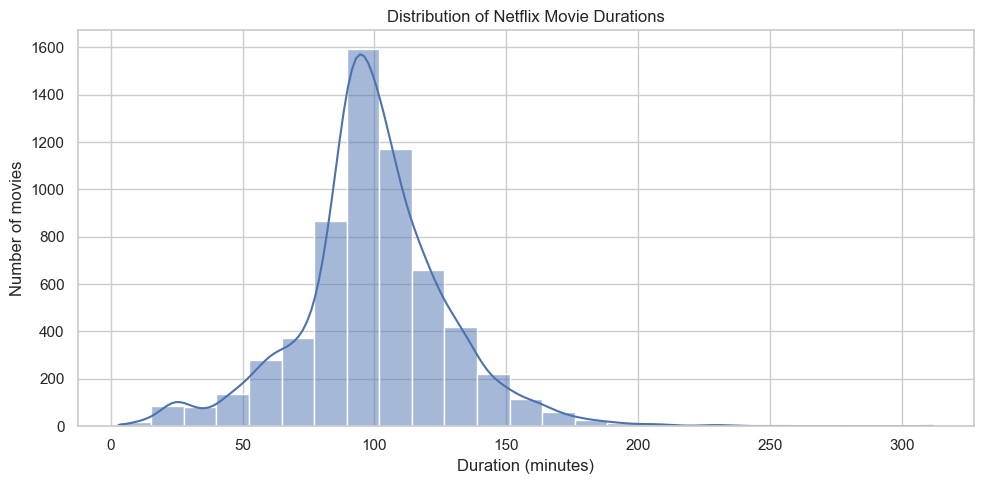

In [18]:
plt.figure(figsize=(10, 5))
sns.histplot(df["movie_duration"].dropna(), bins=25, kde=True)
plt.title("Distribution of Netflix Movie Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of movies")
plt.tight_layout()
plt.show()

### 7. Box plot of movie durations

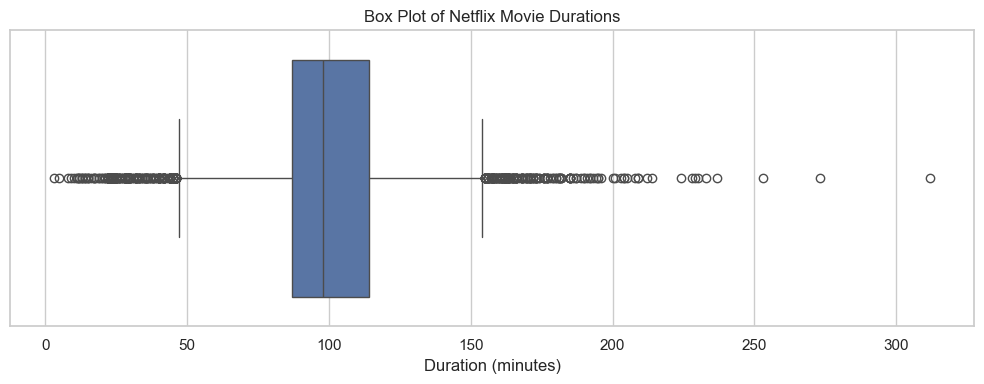

In [19]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df["movie_duration"].dropna())
plt.title("Box Plot of Netflix Movie Durations")
plt.xlabel("Duration (minutes)")
plt.tight_layout()
plt.show()

### 8. Bar plot of content type

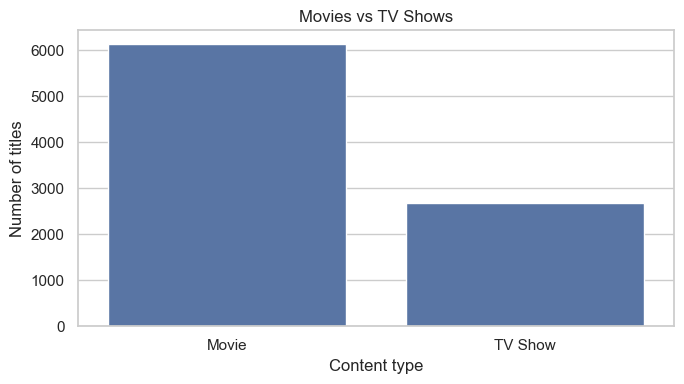

In [20]:
type_counts = df["type"].value_counts()
plt.figure(figsize=(7, 4))
sns.barplot(x=type_counts.index, y=type_counts.values)
plt.title("Movies vs TV Shows")
plt.xlabel("Content type")
plt.ylabel("Number of titles")
plt.tight_layout()
plt.show()

### 9. Top 10 countries by title count

,Country,Title count
0,United States,3690
1,India,1046
2,United Kingdom,806
3,Canada,445
4,France,393
5,Japan,318
6,Spain,232
7,South Korea,231
8,Germany,226
9,Mexico,169


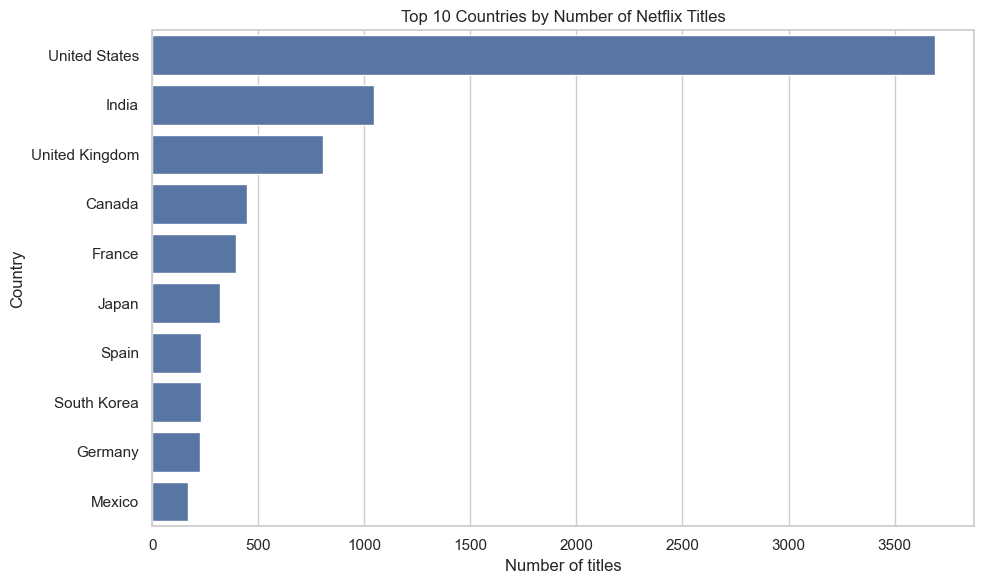

In [21]:
country_counts = (
    df.loc[df["country"].ne("Unknown"), "country"]
      .str.split(",")
      .explode()
      .str.strip()
)
country_counts = country_counts[country_counts.ne("")].value_counts().head(10)

display(country_counts.rename_axis("Country").reset_index(name="Title count"))
plt.figure(figsize=(10, 6))
sns.barplot(x=country_counts.values, y=country_counts.index)
plt.title("Top 10 Countries by Number of Netflix Titles")
plt.xlabel("Number of titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

### 10. Most common content ratings

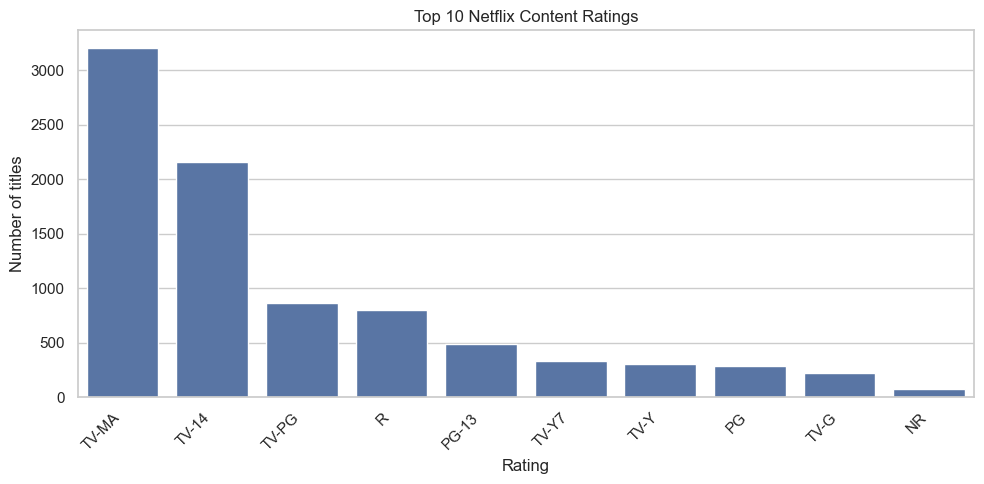

In [22]:
rating_counts = df.loc[df["rating"].ne("Unknown"), "rating"].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=rating_counts.index, y=rating_counts.values)
plt.title("Top 10 Netflix Content Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 11. Print insights from the dataset

In [23]:
valid_ratings = df.loc[df["rating"].ne("Unknown"), "rating"]
most_common_rating = valid_ratings.mode().iloc[0] if not valid_ratings.empty else "Not available"
top_country = country_counts.index[0] if not country_counts.empty else "Not available"

print("EDA INSIGHTS")
print("-" * 40)
print("Total titles:", len(df))
print("Movies:", int(df["type"].eq("Movie").sum()))
print("TV shows:", int(df["type"].eq("TV Show").sum()))
print("Most common rating:", most_common_rating)
print("Top content-producing country in this dataset:", top_country)
print("Average release year:", round(df["release_year"].mean(), 2))
if "outlier_mask" in globals():
    print("Movie-duration outliers detected by IQR:", int(outlier_mask.sum()))

print("\nConclusion:")
print("Manual EDA was performed using Pandas, NumPy, Matplotlib and Seaborn.")
print("Missing values were handled, movie-duration outliers were identified using IQR, and plots were created to study distributions and category patterns.")

EDA INSIGHTS
----------------------------------------
Total titles: 8807
Movies: 6131
TV shows: 2676
Most common rating: TV-MA
Top content-producing country in this dataset: United States
Average release year: 2014.18
Movie-duration outliers detected by IQR: 450

Conclusion:
Manual EDA was performed using Pandas, NumPy, Matplotlib and Seaborn.
Missing values were handled, movie-duration outliers were identified using IQR, and plots were created to study distributions and category patterns.


## Part B — Automated EDA using ydata-profiling

This section uses the **original dataset** (`raw_df`) so the report can show the initial missing values and data-quality issues before cleaning.

In [24]:
from ydata_profiling import ProfileReport

profile = ProfileReport(
    raw_df,
    title="Practical 08 - Netflix Movies and TV Shows EDA Report",
    explorative=True
)

profile.to_file("eda_report.html")
print("Automated EDA report generated: eda_report.html")

/Users/sahil/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/sahil/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Export report to file: 100%|██████████| 1/1 [00:00<00:00, 333.76it/s]

Automated EDA report generated: eda_report.html
